# 2 · Model, training and evaluation

A **U-Net** (CNN encoder + decoder + 1×1 output convolution) for 6-class segmentation of single raw Sentinel-1 scenes.
All variants were trained with `train/train.py` on GPU 0 of the university server (`train/run_experiments.sh`); this
notebook shows their training logs and curves, evaluates them on the **130 test places** and compares them.
Set `RUN_TRAINING = True` below to train E1 again inside this notebook (about 30 minutes on a GPU).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent                  # the s1-lulc folder
sys.path[:0] = [str(ROOT / "data"), str(ROOT / "train"), str(ROOT / "prototype")]
DATA, PREP, RUNS = ROOT / "data" / "tiles_v0", ROOT / "data" / "tiles_v0" / "prepared", ROOT / "train" / "runs"
from classes import CLASS_NAMES, DISPLAY_NAMES, CLASS_COLOURS, N_CLASSES, BUILT
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("project folder:", ROOT)

project folder: /home/jovyan/vault/s1-lulc


In [2]:
RUN_TRAINING = False        # True = train E1 again here (writes runs/E1_notebook, ~30 min on a GPU)
if RUN_TRAINING:
    import subprocess
    cmd = [sys.executable, "-u", str(ROOT / "train" / "train.py"), "--prep-dir", str(PREP), "--name", "E1_notebook",
           "--label", "hyb_s", "--runs-dir", str(RUNS)]
    with subprocess.Popen(cmd, cwd=ROOT / "train", stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as p:
        for line in p.stdout:
            print(line, end="")

## 2.1 The network

ResNet34 encoder (ImageNet start, fine-tuned), decoder with 5 upsampling blocks and skip connections, 1×1 convolution
to 6 class scores per pixel (`train/model.py`). Input: 3 channels = VV, VH, VH−VV in dB, normalised.

In [3]:
import torch
from model import build_model
net = build_model("resnet34", "none").eval()
shapes = []
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.append((n, tuple(o.shape[1:]))))
         for n, m in [("encoder stage %d" % k, s) for k, s in enumerate([net.encoder.layer1, net.encoder.layer2,
                       net.encoder.layer3, net.encoder.layer4], 1)] + [("decoder block %d" % k, b) for k, b in enumerate(net.decoder, 1)]
                      + [("1x1 output", net.head)]]
with torch.no_grad():
    net(torch.zeros(1, 3, 256, 256))
for h in hooks: h.remove()
display(pd.DataFrame(shapes, columns=["layer", "output (channels, H, W)"]))
n_enc = sum(p.numel() for p in net.encoder.parameters()); n_all = sum(p.numel() for p in net.parameters())
print(f"parameters: {n_all / 1e6:.1f} M (encoder {n_enc / 1e6:.1f} M, decoder + head {(n_all - n_enc) / 1e6:.1f} M)")

,layer,"output (channels, H, W)"
0,encoder stage 1,"(64, 64, 64)"
1,encoder stage 2,"(128, 32, 32)"
2,encoder stage 3,"(256, 16, 16)"
3,encoder stage 4,"(512, 8, 8)"
4,decoder block 1,"(256, 16, 16)"
5,decoder block 2,"(128, 32, 32)"
6,decoder block 3,"(64, 64, 64)"
7,decoder block 4,"(32, 128, 128)"
8,decoder block 5,"(16, 256, 256)"
9,1x1 output,"(6, 256, 256)"


parameters: 24.4 M (encoder 21.3 M, decoder + head 3.2 M)


### What goes in and what comes out

One test scene through the trained E1: the input channels, the 6 class scores (logits) per pixel, the softmax
probabilities, and the final map = the class with the highest probability.

input (3, 256, 256) -> logits (6, 256, 256) -> softmax (sums to 1 per pixel) -> argmax map (256, 256)
one pixel (128, 128):


,water,trees,grass & shrub,crops,built-up,bare & snow
logit,-3.790,0.710,-0.930,-1.680,2.190,-2.13
probability,0.002,0.174,0.034,0.016,0.764,0.01


-> predicted class: built-up


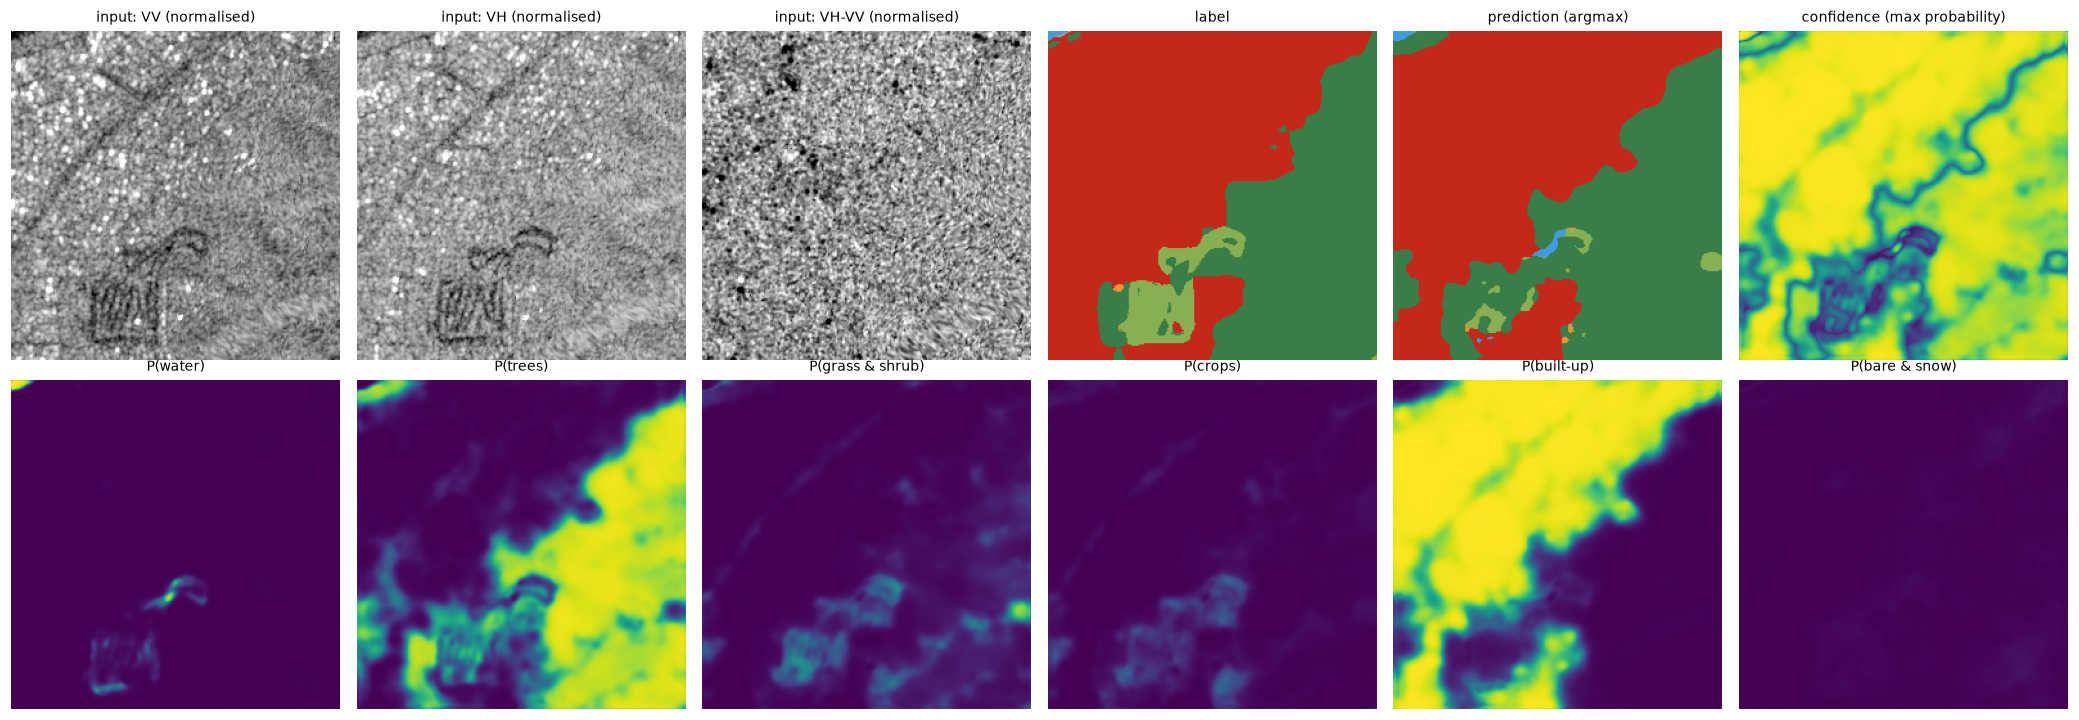

In [4]:
from pipeline import load_model, colourise
model, stats, cfg, device = load_model(RUNS / "E1")
idx = pd.read_csv(PREP / "index.csv"); tt = idx[(idx.status == "ok") & (idx.split == "test")]
zz = np.load(PREP / f"{tt[tt.settlement.isin(['town', 'city'])].iloc[0].tile_id if (tt.settlement.isin(['town', 'city'])).any() else tt.iloc[0].tile_id}.npz")
k = int(zz["best"][zz["best"] >= 0][0]); sc = zz["s1"][k]
mean = np.asarray(stats["mean"], np.float32)[:, None, None]; std = np.asarray(stats["std"], np.float32)[:, None, None]
x = (sc.astype(np.float32) / 100 - mean) / std; x[sc == -32768] = 0
with torch.no_grad():
    logits = model(torch.from_numpy(x)[None].to(device)).float().cpu()[0]
prob = logits.softmax(0).numpy()
print(f"input {tuple(x.shape)} -> logits {tuple(logits.shape)} -> softmax (sums to 1 per pixel) -> argmax map {prob.shape[1:]}")
c0 = prob.shape[1] // 2
print(f"one pixel ({c0}, {c0}):")
display(pd.DataFrame({"logit": [round(float(v), 2) for v in logits[:, c0, c0]],
                      "probability": [round(float(v), 3) for v in prob[:, c0, c0]]}, index=DISPLAY_NAMES).T)
print("-> predicted class:", DISPLAY_NAMES[int(prob[:, c0, c0].argmax())])
fig, ax = plt.subplots(2, 6, figsize=(19, 6.6))
for b, nme in enumerate(["VV", "VH", "VH-VV"]):
    ax[0, b].imshow(x[b], cmap="gray", vmin=-2.5, vmax=2.5); ax[0, b].set_title(f"input: {nme} (normalised)", fontsize=9)
ax[0, 3].imshow(colourise(zz["hyb_s"][int(zz["month"][k])])); ax[0, 3].set_title("label", fontsize=9)
ax[0, 4].imshow(colourise(prob.argmax(0))); ax[0, 4].set_title("prediction (argmax)", fontsize=9)
ax[0, 5].imshow(prob.max(0), cmap="viridis", vmin=0.2, vmax=1); ax[0, 5].set_title("confidence (max probability)", fontsize=9)
for c in range(6):
    ax[1, c].imshow(prob[c], cmap="viridis", vmin=0, vmax=1); ax[1, c].set_title(f"P({DISPLAY_NAMES[c]})", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2.2 The variants

| Run | What changes vs E1 | Question |
| --- | --- | --- |
| E1 | main model: hybrid + smoothed monthly labels, ImageNet fine-tuned, interpolation upsampling | |
| E0 | raw Dynamic World labels | do building footprints + seasonal smoothing help? |
| E1y | annual label (yearly majority) | are stable annual labels better than monthly ones? |
| E2a | ImageNet encoder frozen | transfer learning as feature extraction (lecture 08) |
| E2b | no pretraining (from scratch) | does ImageNet help radar at all? |
| E3 | transposed-convolution upsampling | learned "inverse of convolution" vs interpolation (lecture 07) |
| E5 | 5×5 Lee speckle filter on every scene | does speckle filtering help raw single scenes? |
| E1half | only half of the training places | is the dataset big enough? (learning curve) |

Common setup: CE + Dice loss with class weights, AdamW (lr 1e-3, cosine schedule), batch 32, bf16, random 90°
rotations and flips, balanced sampler, early stopping after 10 epochs without val mIoU gain.

In [5]:
ORDER = ["E1", "E0", "E1y", "E2a", "E2b", "E3", "E5", "E1half"]
runs = [r for r in ORDER if (RUNS / r / "test_metrics.json").exists()]
print("finished runs:", runs)

finished runs: ['E1', 'E0', 'E1y', 'E2a', 'E2b', 'E3', 'E5', 'E1half']


## 2.3 Training logs (as printed during training)

In [6]:
for r in runs:
    log = ROOT / "train" / f"runs_{r}.log"
    if log.exists():
        text = log.read_text()
        text = text[text.find(f"=== {r}"):] if f"=== {r}" in text else text
        print(text.split("Saved to")[0].strip()[-6000:], "\n" + "-" * 100)

Device: cuda (NVIDIA RTX PRO 6000 Blackwell Server Edition), label: hyb_s
Input: single_scenes, no speckle filter
Samples (scenes): train 19852, val 2792; tiles train/val/test 409/61/130
Balanced sampler: effective sample size 12785 of 19852
Class share of training pixels, uniform -> balanced: water 6.3->7.6%, trees 20.9->21.0%, grass_shrub 15.3->16.2%, crops 18.7->16.0%, built 22.2->26.5%, bare_snow 16.5->12.7%
Shared memory /dev/shm is only 64 MB -> data loading in the main process (workers 0)
Model: U-Net resnet34, weights imagenet, upsample interp, 24.4M parameters (24.4M trainable)
Class weights: water 1.40, trees 0.84, grass_shrub 0.96, crops 0.96, built 0.75, bare_snow 1.08
ep   1  loss 1.897/1.745  mIoU 0.378/0.440  val OA 0.629  50s  *best
ep   2  loss 1.536/1.624  mIoU 0.460/0.480  val OA 0.669  45s  *best
ep   3  loss 1.450/1.520  mIoU 0.485/0.516  val OA 0.690  47s  *best
ep   4  loss 1.385/1.565  mIoU 0.505/0.490  val OA 0.681  46s
ep   5  loss 1.348/1.569  mIoU 0.515/0.47

## 2.4 Training curves

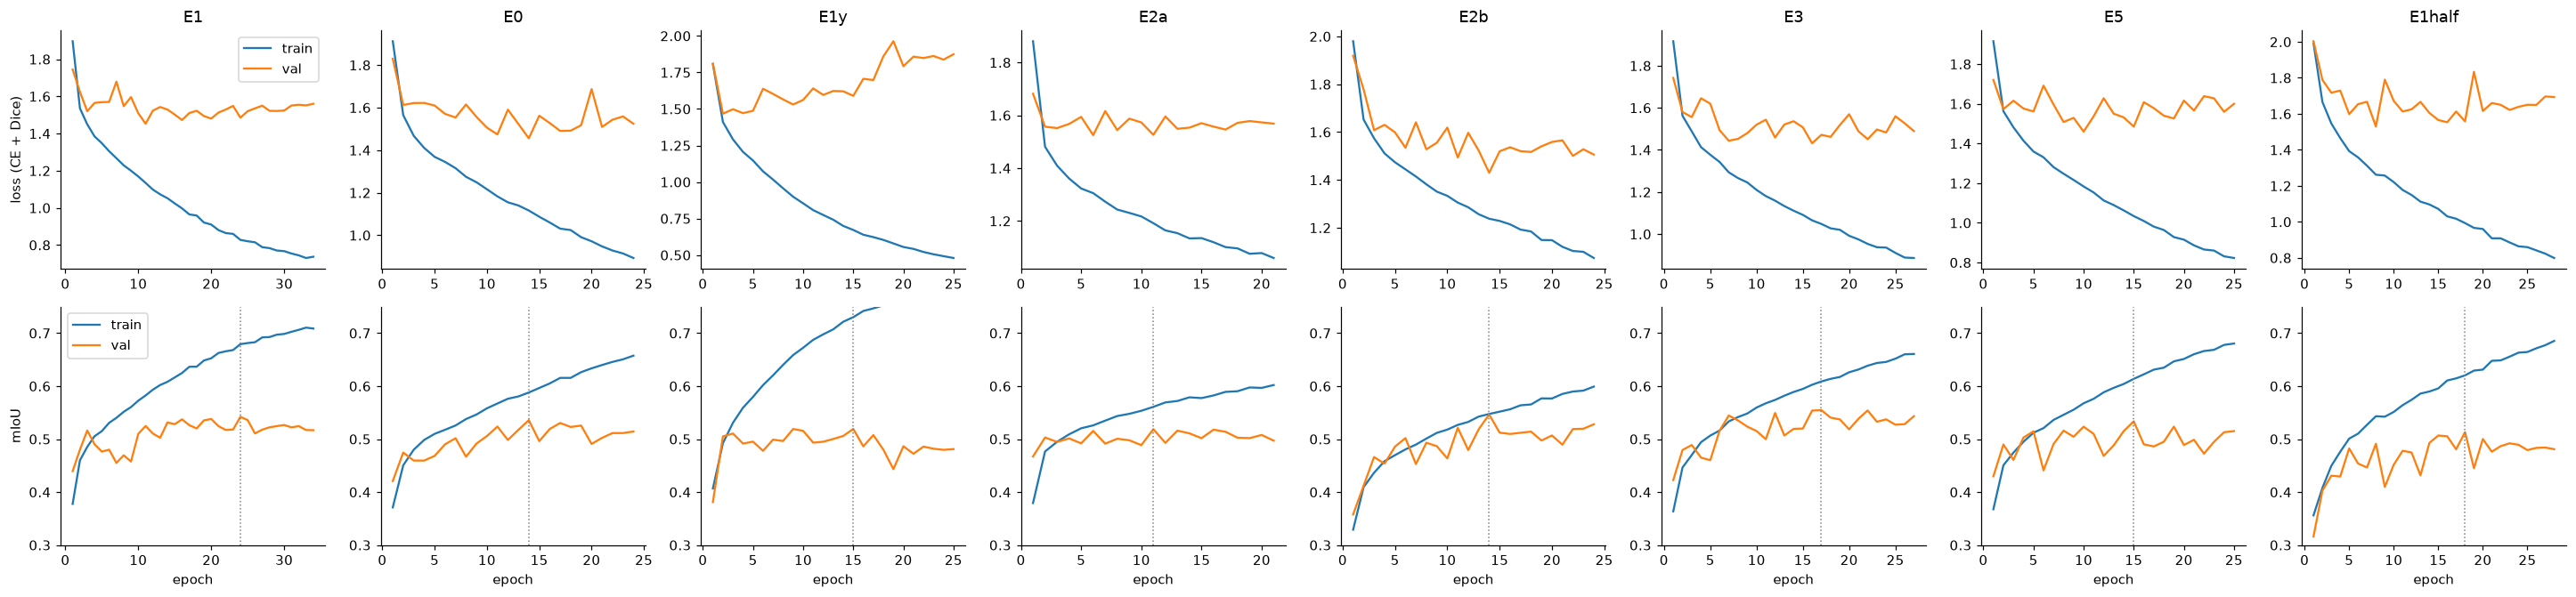

Dotted line = best validation epoch (checkpoint used for testing). Train keeps improving while val flattens:
the model starts to memorise training places and label noise; early stopping keeps the best epoch.


In [7]:
fig, axes = plt.subplots(2, len(runs), figsize=(3.3 * len(runs), 6.2), squeeze=False)
for j, r in enumerate(runs):
    h = pd.read_csv(RUNS / r / "history.csv")
    best = h.val_miou.idxmax()
    axes[0, j].plot(h.epoch, h.train_loss, label="train"); axes[0, j].plot(h.epoch, h.val_loss, label="val")
    axes[1, j].plot(h.epoch, h.train_miou, label="train"); axes[1, j].plot(h.epoch, h.val_miou, label="val")
    axes[1, j].axvline(h.epoch[best], color="grey", ls=":", lw=1)
    axes[0, j].set_title(r); axes[1, j].set_ylim(0.3, 0.75); axes[1, j].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss (CE + Dice)"); axes[1, 0].set_ylabel("mIoU"); axes[0, 0].legend(); axes[1, 0].legend()
plt.tight_layout(); plt.show()
print("Dotted line = best validation epoch (checkpoint used for testing). Train keeps improving while val flattens:")
print("the model starts to memorise training places and label noise; early stopping keeps the best epoch.")

## 2.5 Test results (130 unseen places)

Each run scored against its own training label, with one scene per month (as printed at the end of training).

In [8]:
rows = []
for r in runs:
    m = json.loads((RUNS / r / "test_metrics.json").read_text())
    o, b = m["overall"], m.get("built", {})
    rows.append({"run": r, "OA": o["OA"], "mIoU": o["mIoU"], "macro F1": o["macro_F1"],
                 "built P": b.get("precision"), "built R": b.get("recall"),
                 "village built R": m.get("village_built", {}).get("recall"),
                 "flip rate": m.get("flip_rate", {}).get("prediction"), "best epoch": m.get("best_epoch")})
test = pd.DataFrame(rows).set_index("run")
display(test.round(3))
iou = pd.DataFrame({r: json.loads((RUNS / r / "test_metrics.json").read_text())["per_class_iou"] for r in runs})
iou.index = DISPLAY_NAMES
display(iou.round(3).rename_axis("IoU per class"))

,OA,mIoU,macro F1,built P,built R,village built R,flip rate,best epoch
run,,,,,,,,
E1,0.632,0.487,0.638,0.835,0.807,0.427,0.253,24
E0,0.626,0.487,0.640,0.796,0.792,0.366,0.247,14
E1y,0.647,0.493,0.642,0.821,0.851,0.546,0.224,15
E2a,0.609,0.462,0.613,0.821,0.791,0.423,0.295,11
E2b,0.629,0.482,0.634,0.799,0.825,0.525,0.229,14
E3,0.637,0.490,0.644,0.807,0.838,0.485,0.228,17
E5,0.635,0.493,0.643,0.818,0.819,0.447,0.249,15
E1half,0.607,0.463,0.614,0.789,0.821,0.392,0.250,18


,E1,E0,E1y,E2a,E2b,E3,E5,E1half
IoU per class,,,,,,,,
water,0.729,0.742,0.728,0.704,0.718,0.701,0.748,0.728
trees,0.494,0.472,0.507,0.484,0.496,0.488,0.486,0.435
grass & shrub,0.320,0.354,0.304,0.309,0.321,0.336,0.349,0.317
crops,0.365,0.363,0.402,0.318,0.310,0.367,0.323,0.356
built-up,0.696,0.659,0.718,0.675,0.683,0.698,0.693,0.673
bare & snow,0.318,0.333,0.300,0.284,0.364,0.351,0.357,0.271


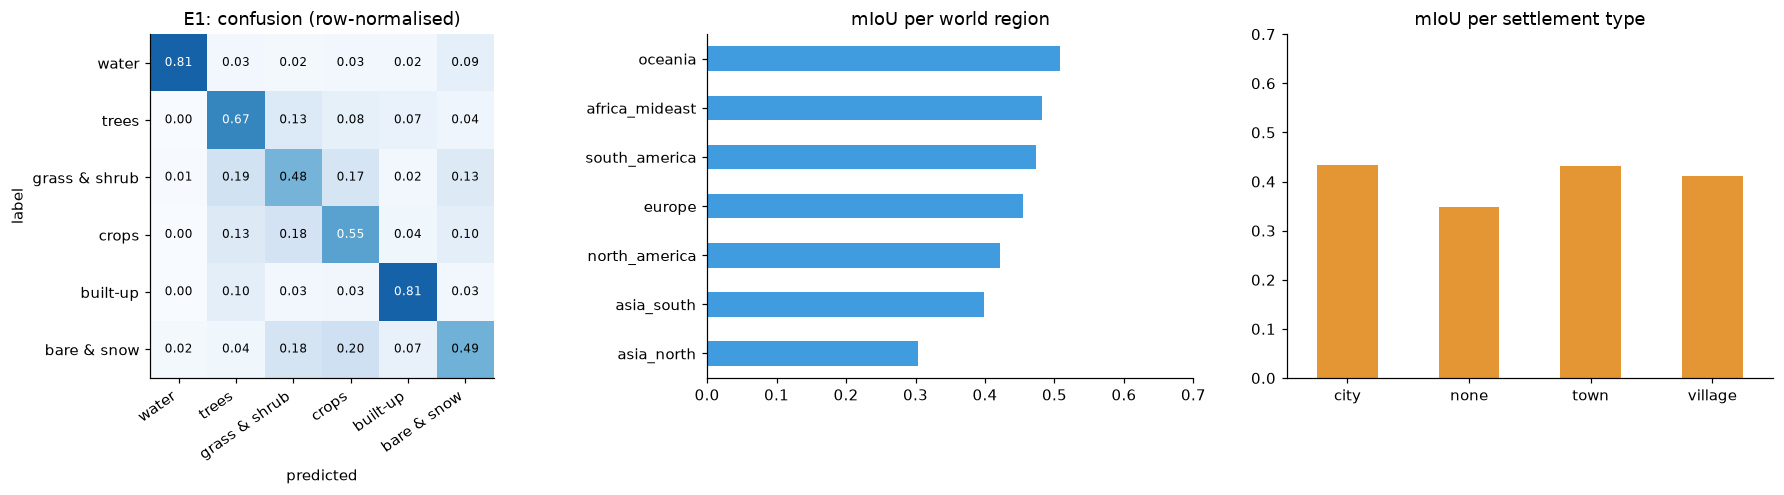

**E1: classification report** (as `sklearn.metrics.classification_report` in the labs, pixel level, each place weighted equally; accuracy = 0.632)

,precision,recall,f1-score,support (pixels)
water,0.882,0.808,0.843,4099726
trees,0.652,0.671,0.661,18515249
grass & shrub,0.493,0.476,0.485,14526981
crops,0.520,0.551,0.535,12905663
built-up,0.835,0.807,0.821,18056755
bare & snow,0.480,0.486,0.483,9171530
macro avg,0.644,0.633,0.638,77275907
weighted avg,0.635,0.632,0.633,77275907


In [9]:
MAIN = "E1"
m = json.loads((RUNS / MAIN / "test_metrics.json").read_text())
f1 = pd.Series(m["per_class_f1"]); f1.index = DISPLAY_NAMES
cm = pd.read_csv(RUNS / MAIN / "test_confusion.csv", index_col=0).to_numpy(float)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
im = ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(6), DISPLAY_NAMES, rotation=35, ha="right"); ax[0].set_yticks(range(6), DISPLAY_NAMES)
for i in range(6):
    for j in range(6):
        ax[0].text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if cmn[i, j] > .5 else "k")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("label"); ax[0].set_title(f"{MAIN}: confusion (row-normalised)")
pd.Series({k: v["mIoU"] for k, v in m["per_region"].items()}).sort_values().plot.barh(ax=ax[1], color="#419bdf")
ax[1].set_title("mIoU per world region"); ax[1].set_xlim(0, 0.7)
pd.Series({k: v["mIoU"] for k, v in m["per_settlement"].items()}).plot.bar(ax=ax[2], rot=0, color="#e49635")
ax[2].set_title("mIoU per settlement type"); ax[2].set_ylim(0, 0.7)
plt.tight_layout(); plt.show()
tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
f1c = 2 * prec * rec / np.maximum(prec + rec, 1e-9); sup = cm.sum(1)
rep_ = pd.DataFrame({"precision": prec, "recall": rec, "f1-score": f1c, "support (pixels)": sup}, index=DISPLAY_NAMES)
rep_.loc["macro avg"] = [prec.mean(), rec.mean(), f1c.mean(), sup.sum()]
rep_.loc["weighted avg"] = [np.average(prec, weights=sup), np.average(rec, weights=sup), np.average(f1c, weights=sup), sup.sum()]
display(Markdown(f"**{MAIN}: classification report** (as `sklearn.metrics.classification_report` in the labs, pixel level, "
                 f"each place weighted equally; accuracy = {tp.sum() / cm.sum():.3f})"))
display(rep_.round(3).astype({"support (pixels)": int}))

## 2.6 From single scenes to 12 monthly maps

The model reads one raw scene at a time. The prototype needs one map per month; we compared four ways of combining a
month's scene predictions (`train/eval_change.py`), all scored against the **same** labels (hyb_s) so the runs are
comparable. *Month mean* = class probabilities averaged over all scenes of the month.

In [10]:
import subprocess
RUN_MISSING_EVAL = True     # runs eval_change.py (~5 min per run on a GPU) where change_eval.csv is missing
for r in runs:
    if RUN_MISSING_EVAL and not (RUNS / r / "change_eval.csv").exists():
        print(f"evaluating {r} ...")
        subprocess.run([sys.executable, str(ROOT / "train" / "eval_change.py"), "--run", str(RUNS / r),
                        "--prep-dir", str(PREP), "--label", "hyb_s"], cwd=ROOT / "train", check=False)
ce = {r: pd.read_csv(RUNS / r / "change_eval.csv", index_col=0) for r in runs if (RUNS / r / "change_eval.csv").exists()}
if "E1" in ce:
    display(Markdown("**E1: four ways to build the monthly maps**")); display(ce["E1"].round(3))
cols = ["OA", "mIoU", "built_P", "built_R", "flip_rate", "built_false_change", "false_new_ha_km2"]
fair = pd.DataFrame({r: d.loc[d.index.str.startswith("B")].iloc[0] for r, d in ce.items()}).T
if len(fair):
    display(Markdown("**All runs, month-mean maps, same reference labels (hyb_s): the fair comparison**"))
    display(fair[cols].round(3))

**E1: four ways to build the monthly maps**

,OA,mIoU,built_P,built_R,flip_rate,built_false_change,new_built_pred_ha_km2,new_built_label_ha_km2,false_new_ha_km2,change_P,change_R
strategy,,,,,,,,,,,
A best scene,0.637,0.492,0.837,0.812,0.251,0.044,0.547,0.802,0.507,0.073,0.050
"D best, 1 orbit",0.640,0.497,0.838,0.815,0.239,0.041,0.545,0.803,0.503,0.076,0.052
B month mean,0.662,0.522,0.846,0.826,0.149,0.022,0.559,0.806,0.520,0.070,0.048
"C mean, 1 orbit",0.659,0.518,0.846,0.829,0.157,0.023,0.556,0.806,0.516,0.073,0.050


**All runs, month-mean maps, same reference labels (hyb_s): the fair comparison**

,OA,mIoU,built_P,built_R,flip_rate,built_false_change,false_new_ha_km2
E1,0.662,0.522,0.846,0.826,0.149,0.022,0.520
E0,0.658,0.523,0.833,0.809,0.144,0.024,0.447
E1y,0.648,0.501,0.816,0.855,0.128,0.020,0.593
E2a,0.643,0.497,0.830,0.819,0.176,0.025,0.464
E2b,0.651,0.509,0.805,0.844,0.141,0.024,0.474
E3,0.661,0.522,0.815,0.854,0.133,0.020,0.392
E5,0.661,0.524,0.827,0.838,0.141,0.022,0.459
E1half,0.636,0.498,0.797,0.838,0.141,0.024,0.485


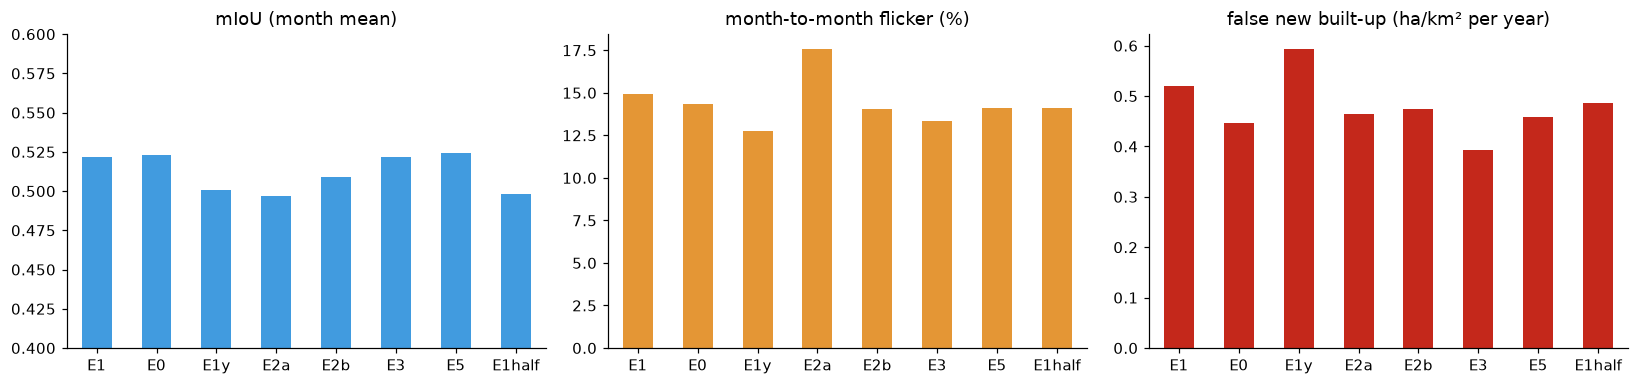

Differences of about +-0.02 mIoU are within run-to-run noise.


In [11]:
if len(fair):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    fair["mIoU"].plot.bar(ax=ax[0], rot=0, color="#419bdf"); ax[0].set_ylim(0.4, 0.6); ax[0].set_title("mIoU (month mean)")
    (fair["flip_rate"] * 100).plot.bar(ax=ax[1], rot=0, color="#e49635"); ax[1].set_title("month-to-month flicker (%)")
    fair["false_new_ha_km2"].plot.bar(ax=ax[2], rot=0, color="#c4281b"); ax[2].set_title("false new built-up (ha/km² per year)")
    plt.tight_layout(); plt.show()
    print("Differences of about +-0.02 mIoU are within run-to-run noise.")

## 2.7 Is the dataset big enough? (learning curve)

In [12]:
if "E1half" in ce and "E1" in ce:
    lc = pd.DataFrame({"E1half (50% of training places)": ce["E1half"].iloc[2], "E1 (100%)": ce["E1"].iloc[2]}).T
    display(lc[cols].round(3))
elif "E1half" in runs:
    display(test.loc[[r for r in ["E1half", "E1"] if r in runs]])
else:
    print("E1half not trained yet:  python3 train.py --prep-dir ../data/tiles_v0/prepared --name E1half --label hyb_s --train-frac 0.5")

,OA,mIoU,built_P,built_R,flip_rate,built_false_change,false_new_ha_km2
E1half (50% of training places),0.636,0.498,0.797,0.838,0.141,0.024,0.485
E1 (100%),0.662,0.522,0.846,0.826,0.149,0.022,0.520


## 2.8 Final setting for the prototype: ensemble and change rule

No retraining (`train/eval_ensemble.py`): the probabilities of the 4 best models are averaged (ensemble), test-time
augmentation (flipped copies) is tried, and two rules for **new built-up** are compared: *argmax* (built in most end
months, in none of the start months) and *confident* (mean built-up probability ≥ HI at the end and < LO in every
start month).

In [13]:
f = RUNS / "ensemble_eval.csv"
if f.exists():
    ee_ = pd.read_csv(f)
    display(Markdown("**Maps**"))
    display(ee_[ee_.change_rule == "argmax"].set_index("variant")[["OA", "mIoU", "built_P", "built_R", "flip_rate", "built_false_change"]].round(3))
    display(Markdown("**New built-up over 12 months** (false = not new in the labels; the labels themselves are noisy)"))
    display(ee_.set_index(["variant", "change_rule"])[["new_ha_km2", "false_new_ha_km2", "change_P"]].round(3))
    try:
        from pipeline import PROTOTYPE
    except ImportError:   # older prototype/pipeline.py on this machine
        PROTOTYPE = {"runs": ["E3", "E1", "E5", "E2b"], "tta": False, "change_rule": "confident", "hi": 0.5, "lo": 0.2}
    display(Markdown(f"**Prototype uses:** models {' + '.join(PROTOTYPE['runs'])}, TTA {PROTOTYPE['tta']}, "
                     f"{PROTOTYPE['change_rule']} rule (HI {PROTOTYPE['hi']}, LO {PROTOTYPE['lo']}). The ensemble adds about "
                     "+2 mIoU points and less flicker; TTA adds almost nothing at 4x the time; the confident rule removes "
                     "almost all false new built-up but is strict, so the app also shows the argmax result as an upper bound."))
else:
    print("ensemble_eval.csv not found: run train/eval_ensemble.py")

**Maps**

,OA,mIoU,built_P,built_R,flip_rate,built_false_change
variant,,,,,,
E3 single,0.661,0.522,0.815,0.854,0.133,0.020
E3 + TTA,0.663,0.525,0.814,0.857,0.134,0.018
ensemble (E3+E1+E5+E2b),0.682,0.544,0.826,0.852,0.116,0.018
ensemble + TTA,0.685,0.547,0.826,0.853,0.114,0.017


**New built-up over 12 months** (false = not new in the labels; the labels themselves are noisy)

new_ha_km2  false_new_ha_km2  change_P
variant                 change_rule                                              
E3 single               argmax                  0.431             0.392     0.090
                        confident 0.5/0.2       0.018             0.009     0.505
                        confident 0.6/0.2       0.010             0.004     0.574
                        confident 0.7/0.3       0.011             0.006     0.497
E3 + TTA                argmax                  0.424             0.386     0.090
                        confident 0.5/0.2       0.013             0.006     0.570
                        confident 0.6/0.2       0.008             0.003     0.615
                        confident 0.7/0.3       0.011             0.005     0.523
ensemble (E3+E1+E5+E2b) argmax                  0.452             0.411     0.091
                        confident 0.5/0.2       0.011             0.004     0.626
                        confident 0.6/0.2       0.008             0.003     0.604
                        confident 0.7/0.3       0.011             0.005     0.490
ensemble + TTA          argmax                  0.445             0.403     0.094
                        confident 0.5/0.2       0.011             0.004     0.610
                        confident 0.6/0.2       0.008             0.003     0.607
                        confident 0.7/0.3       0.011             0.005     0.490

**Prototype uses:** models E3 + E1 + E5 + E2b, TTA False, confident rule (HI 0.5, LO 0.2). The ensemble adds about +2 mIoU points and less flicker; TTA adds almost nothing at 4x the time; the confident rule removes almost all false new built-up but is strict, so the app also shows the argmax result as an upper bound.

## 2.9 Example predictions on test places

Label, one scene per month, and the month-mean map (what the prototype shows).

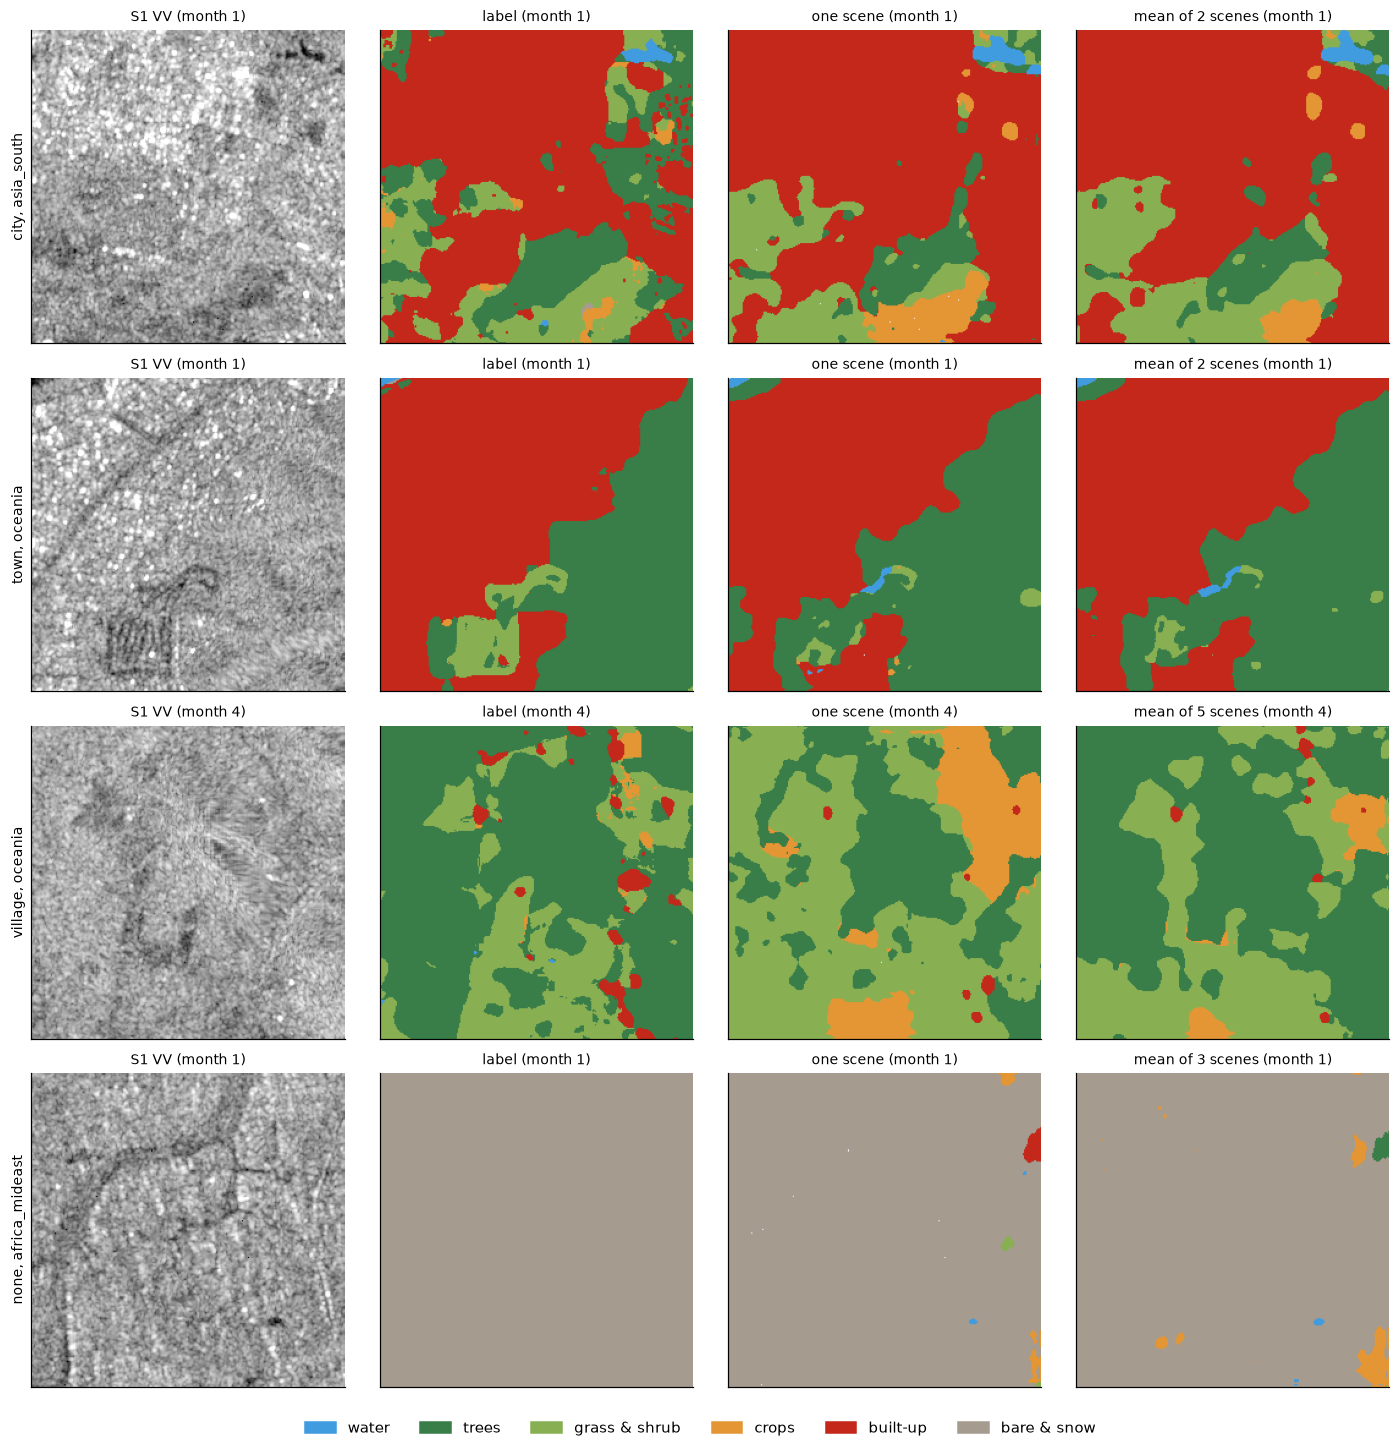

In [14]:
from pipeline import load_model, colourise
from eval_change import scene_probs, monthly_maps
model, stats, cfg, device = load_model(RUNS / "E1")
mean = np.asarray(stats["mean"], np.float32)[:, None, None]; std = np.asarray(stats["std"], np.float32)[:, None, None]
idx = pd.read_csv(PREP / "index.csv"); test_tiles = idx[(idx.status == "ok") & (idx.split == "test")]
def well_labelled(df, min_frac=0.5):
    """first place of df that has at least one month with >= min_frac labelled pixels and radar data"""
    for r in df.itertuples():
        zz_ = np.load(PREP / f"{r.tile_id}.npz")
        if any(zz_["n"][m] > 0 and (zz_["hyb_s"][m] >= 0).mean() >= min_frac for m in range(12)):
            return df[df.tile_id == r.tile_id]
    return df.head(1)
picks = pd.concat([well_labelled(test_tiles[test_tiles.settlement == s]) for s in ["city", "town", "village", "none"]])
fig, axes = plt.subplots(len(picks), 4, figsize=(13, 3.3 * len(picks)), squeeze=False)
for i, r in enumerate(picks.itertuples()):
    z = np.load(PREP / f"{r.tile_id}.npz")
    probs = scene_probs(model, z["s1"], mean, std, torch.device(device), bool(cfg.get("lee", False)))
    nod = (z["s1"] == -32768).any(1)
    a = monthly_maps(probs, nod, z["month"].astype(int), z["day"].astype(int), z["valid"], z["orbit"].astype(str), "best", False)
    b = monthly_maps(probs, nod, z["month"].astype(int), z["day"].astype(int), z["valid"], z["orbit"].astype(str), "mean", False)
    labelled = np.array([(z["hyb_s"][mm] >= 0).mean() if z["n"][mm] > 0 else -1 for mm in range(12)])
    m = int(np.argmax(labelled))          # the month with the most labelled pixels (and radar data)
    vv = z["s1"][z["best"][m], 0].astype(float) / 100
    axes[i, 0].imshow(vv, cmap="gray", vmin=-25, vmax=0); axes[i, 1].imshow(colourise(z["hyb_s"][m]))
    axes[i, 2].imshow(colourise(a[m])); axes[i, 3].imshow(colourise(b[m]))
    axes[i, 0].set_ylabel(f"{r.settlement}, {r.region}", fontsize=9)
    for j, t in enumerate(["S1 VV", "label", "one scene", f"mean of {int(z['n'][m])} scenes"]):
        axes[i, j].set_title(f"{t} (month {m + 1})", fontsize=9); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOURS]
fig.legend(handles, DISPLAY_NAMES, loc="lower center", ncol=6, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()